In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../Project_with_Jon/GPs.jl")
include("../Project_with_Jon/functions.jl")
include("../Project_with_Jon/myfuncs.jl")
include("../Project_with_Jon/integrators.jl")
include("../Project_with_Jon/util_shoji.jl")


SystemError: SystemError: opening file "/Users/shoji/Project_with_Jon/Project_with_Jon/GPs.jl": No such file or directory

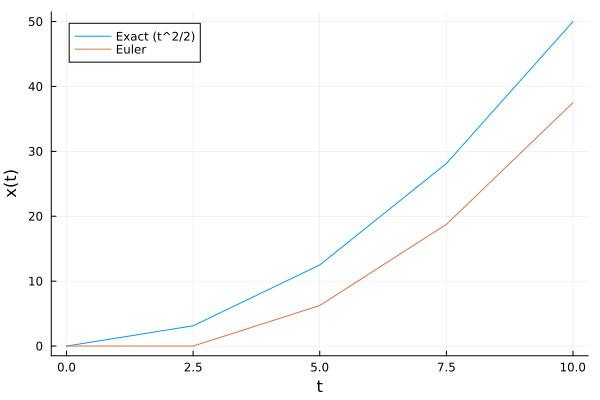

In [7]:
u0 = 0.0
dt = 2.5
T = 10
tspan = 0:dt:T

function reaction(u, p, t)
    return t
end

sol = exact(reaction, u0, tspan, Tsit5(), 1e-10, 1e-10)

numsol, _ = numerical_integration(
    reaction,
    Euler,
    u0,
    dt,
    length(tspan),
    1
)

plot(tspan, sol,
    label="Exact (t^2/2)",
    xlabel="t",
    ylabel="x(t)"
)

plot!(tspan, numsol,
    label="Euler"
)



t_obs:[0.0, 2.5, 5.0, 7.5]
y:[0.0, 0.0, 2.5, 5.0, 7.5]
m_y:[0.0, 0.0, 0.0, 0.0, 0.0]
m_x:(500,)
 Ks * (K \ (y-m_y)):(500,)


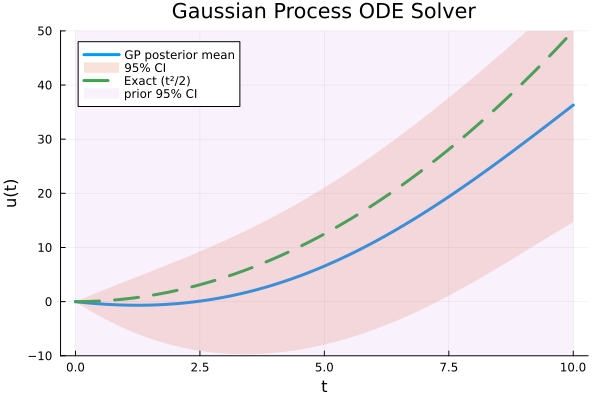

"/Users/shoji/Project_with_Jon/a.png"

In [8]:
using LinearAlgebra
using Plots



ℓ =10.0
σf =100.0
prior_mean = 0.0
obs_noise = dt*2

# =====================================================
# Cov(L_i,L_j)
#
# L_i u =
# (u(t_i+dt)-u(t_i))/dt
# =====================================================

function K_LL(ts; dt, ℓ=1.0, σf=1.0)

    n = length(ts)

    K = zeros(n,n)

    for i in 1:n
        for j in 1:n

            ti = ts[i]
            tj = ts[j]

            K[i,j] =
                (
                    rbf_kernel(ti+dt,tj+dt; ℓ=ℓ, σf=σf)
                    -
                    rbf_kernel(ti+dt,tj; ℓ=ℓ, σf=σf)
                    -
                    rbf_kernel(ti,tj+dt; ℓ=ℓ, σf=σf)
                    +
                    rbf_kernel(ti,tj; ℓ=ℓ, σf=σf)
                ) / dt^2

        end
    end

    K
end

# =====================================================
# Observation covariance
#
# observations:
#
# [u(0),
#  L0u,
#  L1u,
#  ...]
# =====================================================

function build_observation_covariance(ts;
                                      dt,
                                      ℓ,
                                      σf)

    n = length(ts)

    K = zeros(n+1,n+1)

    #
    # Cov(u(0),u(0))
    #

    K[1,1] =
        rbf_kernel(
            0.0,
            0.0;
            ℓ=ℓ,
            σf=σf
        )

    #
    # Cov(u(0),Lj)
    #

    for j in 1:n

        tj = ts[j]

        K[1,j+1] =
            (
                rbf_kernel(
                    0.0,
                    tj+dt;
                    ℓ=ℓ,
                    σf=σf
                )
                -
                rbf_kernel(
                    0.0,
                    tj;
                    ℓ=ℓ,
                    σf=σf
                )
            ) / dt

        K[j+1,1] =
            K[1,j+1]

    end

    #
    # Cov(Li,Lj)
    #

    K[2:end,2:end] .=
        K_LL(
            ts;
            dt=dt,
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# Cov(u(t),L_j)
# =====================================================

function K_starL(X_test,
                 ts;
                 dt,
                 ℓ=1.0,
                 σf=1.0)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n)

    for i in 1:m
        for j in 1:n

            t = X_test[i]
            tj = ts[j]

            K[i,j] =
                (
                    rbf_kernel(t,tj+dt; ℓ=ℓ, σf=σf)
                    -
                    rbf_kernel(t,tj; ℓ=ℓ, σf=σf)
                ) / dt

        end
    end

    K
end



# =====================================================
# Cross covariance
#
# Cov(u(t), observations)
# =====================================================

function build_cross_covariance(X_test,
                                ts;
                                dt,
                                ℓ,
                                σf)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n+1)

    #
    # Cov(u(t),u(0))
    #

    for i in 1:m

        K[i,1] =
            rbf_kernel(
                X_test[i],
                0.0;
                ℓ=ℓ,
                σf=σf
            )

    end

    #
    # Cov(u(t),Lj)
    #

    K[:,2:end] .=
        K_starL(
            X_test,
            ts;
            dt=dt,
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# ODE
#
# u'(t)=t
#
# exact:
# u(t)=t²/2
# =====================================================

#t_obs =
#    collect(0:dt:8)
t_obs =
    collect(0:dt:10 - dt) #- dt

println("t_obs:", t_obs)

rhs =
    collect(t_obs)

#
# observations:
#
# u(0)=0
#
# (u(t_i+dt)-u(t_i))/dt = t_i
#

y =
    vcat(
        [0.0],
        rhs
    )

#y .-= prior_mean

println("y:", y)


# =====================================================
# Posterior
# =====================================================

X_test =
    collect(
        range(
            0,
            10,
            length=500
        )
    )

K =
    build_observation_covariance(
        t_obs;
        dt=dt,
        ℓ=ℓ,
        σf=σf
    )

#K += 1e-10I


#Observation Noise
K[2:end,2:end] += obs_noise .* I

Ks =
    build_cross_covariance(
        X_test,
        t_obs;
        dt=dt,
        ℓ=ℓ,
        σf=σf
    )

Kss =
    kernel_matrix(
        X_test,
        X_test;
        ℓ=ℓ,
        σf=σf
    )

m_y = vcat([prior_mean],  zeros(length(t_obs)))
println("m_y:", m_y)
m_x = fill(prior_mean, length(X_test))
println("m_x:", m_x.size)
println(" Ks * (K \\ (y-m_y)):", (Ks * (K \ (y-m_y))).size)

μ =   
 m_x + Ks * (K \ (y-m_y))




Σ =
    Kss -
    Ks * (K \ Ks')

std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================

u_exact(t) =
    t^2 / 2


# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

μ_prior = zeros(length(X_test))

Kss = kernel_matrix(
    X_test,
    X_test;
    ℓ=ℓ,
    σf=σf
)

std_prior = sqrt.(diag(Kss))


μ_prior = fill(prior_mean, length(X_test))

plot!(
    X_test,
    ylims = (-10, 50),
    μ_prior .+ 1.96 .* std_prior,
    fillrange = μ_prior .- 1.96 .* std_prior,
    fillalpha = 0.1,
    linealpha = 0,
    label = "prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver")

display(current())

savefig("a.png")

In [9]:
ℓ_grid = [0.001, 0.1, 0.5, 1.0, 3.0, 5.0, 10.0, 100]

σf_grid = [0.0001, 0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 500]

prior_mean = 0.0  # ← スカラーにする

scores = zeros(
    length(ℓ_grid),
    length(σf_grid)
)

# ==========================================
# Grid Search
# ==========================================

for (i, ℓ) in enumerate(ℓ_grid)
    for (j, σf) in enumerate(σf_grid)

        scores[i,j] =
            log_marginal_extended2(
                t_obs,
                y;
                dt=dt,
                ℓ=ℓ,
                σf=σf,
                prior_mean=prior_mean,
                obs_noise = obs_noise
            )

    end
end

for (j, σf) in enumerate(σf_grid)

    println()
    println("========================================")
    println("σf = ", σf)
    println("========================================")

    println(rpad("ℓ", 10), "score")

    for (i, ℓ) in enumerate(ℓ_grid)
        println(rpad(string(ℓ), 10),
                round(scores[i,j], digits=4))
    end
end

best_linear_idx = argmax(scores)

best_i, best_j =
    Tuple(CartesianIndices(scores)[best_linear_idx])

best_ℓ = ℓ_grid[best_i]
best_σf = σf_grid[best_j]

println()
println("Best parameters")
println("----------------")
println("best ℓ    = ", best_ℓ)
println("best σf   = ", best_σf)
println("best score = ", scores[best_i,best_j])




σf = 0.0001
ℓ         score
0.001     -7.3532
0.1       -7.3532
0.5       -7.3532
1.0       -7.3532
3.0       -7.3532
5.0       -7.3532
10.0      -7.3532
100.0     -7.3532

σf = 0.001
ℓ         score
0.001     -9.6558
0.1       -9.6558
0.5       -9.6558
1.0       -9.6558
3.0       -9.6558
5.0       -9.6558
10.0      -9.6558
100.0     -9.6558

σf = 0.01
ℓ         score
0.001     -11.9584
0.1       -11.9584
0.5       -11.9584
1.0       -11.9584
3.0       -11.9584
5.0       -11.9584
10.0      -11.9584
100.0     -11.9584

σf = 0.03
ℓ         score
0.001     -13.0569
0.1       -13.0569
0.5       -13.0569
1.0       -13.0569
3.0       -13.0569
5.0       -13.057
10.0      -13.057
100.0     -13.057

σf = 0.1
ℓ         score
0.001     -14.2597
0.1       -14.2597
0.5       -14.2597
1.0       -14.2597
3.0       -14.2596
5.0       -14.2603
10.0      -14.2607
100.0     -14.261

σf = 0.3
ℓ         score
0.001     -15.3481
0.1       -15.3481
0.5       -15.3481
1.0       -15.3479
3.0       -15.3475
5.

In [10]:
println()
println("================ GRID TABLE ================")

# header
print(rpad("σf \\ ℓ", 10))
for ℓ in ℓ_grid
    print(rpad(string(ℓ), 12))
end
println()

# body
for (j, σf) in enumerate(σf_grid)
    print(rpad(string(σf), 10))
    for (i, ℓ) in enumerate(ℓ_grid)
        print(rpad(round(scores[i,j], digits=4), 12))
    end
    println()
end


================ GRID TABLE ================
σf \ ℓ    0.001       0.1         0.5         1.0         3.0         5.0         10.0        100.0       
0.0001    -7.3532     -7.3532     -7.3532     -7.3532     -7.3532     -7.3532     -7.3532     -7.3532     
0.001     -9.6558     -9.6558     -9.6558     -9.6558     -9.6558     -9.6558     -9.6558     -9.6558     
0.01      -11.9584    -11.9584    -11.9584    -11.9584    -11.9584    -11.9584    -11.9584    -11.9584    
0.03      -13.0569    -13.0569    -13.0569    -13.0569    -13.0569    -13.057     -13.057     -13.057     
0.1       -14.2597    -14.2597    -14.2597    -14.2597    -14.2596    -14.2603    -14.2607    -14.261     
0.3       -15.3481    -15.3481    -15.3481    -15.3479    -15.3475    -15.3537    -15.3574    -15.3596    
1.0       -16.4413    -16.4413    -16.4413    -16.4387    -16.4328    -16.4984    -16.5392    -16.5632    
3.0       -16.8399    -16.8399    -16.8399    -16.8199    -16.7151    -17.1214    -17.4509    -17.